# **Ottimizzazione di Performance Cognitive o Sportive tramite Machine Learning su Dati Biometrici**

<div style="border-left: 3px solid #000; padding: 5px 15px; margin: 10px 0;">
<span style="color: #666; font-size: 19px; letter-spacing: 1.5px;">PROGETTO INGEGNERIA INFORMATICA · A.A. 2025/2026</span>
</div>

**Luis Mariduena** & **Edoardo Sorgentone**

---

# **Introduzione al progetto**
L'obbiettivo di questo progetto è lo sviluppo di un modello di ML che riesca a prevedere la performance cognitiva di un utente basandosi sui dati acquisiti da dispositivi **wearable e da dati sulla nutrizione** degli utenti(macro assunte giornalmente). La letteratura scientifica e l'esperienza quotidiana dei nostri utenti dimostrano una evidente correlazione tra nutrizione e performance cognitive. A causa della crescente frenesia dei ritmi lavorativi e accademici, i pasti rappresentano frequentemente il primo sacrificio, spesso si ricorre infatti a pasti veloci e poco sani.

In particolare, la nostra ricerca non si ferma alla sola correlazione tra dati wearable/nutrizionali e performance cognitive, ma ottimizzeremo gli input per ottenere un output(performance cognitiva) desiderata.

# **1. Pre Processing Dataset**


In questa fase effettueremo tutte le operazioni di data cleaning, unione di dataset,
## **1.1 - Apertura del dataset e breve descrizione**


Apertura dei file da google drive:

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
# Caricamento (usando on_bad_lines per sicurezza)
path_n = "drive/MyDrive/df.csv"
path_w = "drive/MyDrive/wearable.csv"

df_nutrition = pd.read_csv(path_n, sep=',', on_bad_lines='skip')
df_wearable = pd.read_csv(path_w)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Il dataset wearable è composto quindi da 280 righe e 41 colonne. Ogni riga è riferita a un particolare test cognitivo effettuato in un dato giorno da un certo sogetto. In ogni colonna possono esserci dati come l'HR in un'ora del giorno, l'informazione su quanto l'utente ha dormito la notte prima del test cognitivo.

Quanto al test cognitivo, la performance dei vari utenti è misurata con il punteggio **C-score**, che è un punteggio composto delle seguenti metriche:


1.   **memoria**: punteggio in compiti di memoria a breve termine
2.   **logica**: capacità di ragionamento logico
3.   **capacità verbali**: fluenza verbale o la capacità di recupero lessicale



Le colonne cognitive hanno 85 valori non nulli su 280 righe. Invece i dati biometrici sono quasi sempre presenti.Bisogna quindi valutare le tecniche di **data imputation** da applicare.

Si potrebbero inoltre creare le seguenti feature:

1.   **Efficienza del Sonno**: sleepTimeSeconds / awakeSleepSeconds

2.  **Resilienza allo Stress**: La differenza tra lo stress medio e il c_score. Esistono utenti "resilienti" che mantengono un alto punteggio cognitivo anche con alto stress?


Ecco le feature presenti nel dataset originale:



In [ ]:
df_wearable.columns

Index(['Unnamed: 0', 'ACC_night', 'ACC_night_timestamps', 'C_SCORE',
       'HR_day_1h', 'HR_day_1h_timestamps', 'HR_night_imputed',
       'HR_night_timestamps', 'HR_night_with_timestamps', 'RR_day_1h',
       'RR_day_1h_timestamps', 'RR_night_imputed', 'RR_night_timestamps',
       'RR_night_with_timestamps', 'admin_dt', 'admin_time', 'age',
       'awakeCount', 'awakeSleepSeconds', 'c_score', 'data', 'deepPercentage',
       'deepSleepSeconds', 'height_cm', 'lightPercentage', 'lightSleepSeconds',
       'memory', 'napTimeSeconds', 'reasoning', 'remPercentage',
       'remSleepSeconds', 'sex', 'sleepTimeSeconds', 'source_dataset',
       'stress', 'stress_source_col', 'time_source_col', 'timeseries_id',
       'userID', 'verbal', 'weight_kg'],
      dtype='object')

In [ ]:
print("DATASET NUTRIZIONE:")
df_nutrition.head(5)

DATASET NUTRIZIONE:


,ID,Carboidrati_5,Proteine_5,Grassi_5,Kcal_5,carbs_over_proteins_5,Carboidrati_4,Proteine_4,Grassi_4,Kcal_4,...,ALTEZZA,PESO,ETA',BMI,VO2 (ml/min),Ve (l/min),Resting Metabolic Rate (RMR) (Kcal/day),% Massa grassa,% Massa magra (100-% Massa Grassa),% Acqua Corporea
0,ID1_15-01_15-50,"23,4",3,"7,8",180,"7,8","12,2","19,4","19,4",300,...,173,52,24,"17,37",182,"5,2","1360,14","22,17","77,83","65,15"
1,ID1_17-01_10-25,12,"0,8","0,2",50,15,"12,22","49,4","3,38",499,...,173,52,24,"17,37",182,"5,2","1360,14","22,17","77,83","65,15"
2,ID1_22-01_19-10,"82,75",23,"31,75",700,"3,6",15,10,6,130,...,173,52,24,"17,37",182,"5,2","1360,14","22,17","77,83","65,15"
3,ID1_24-01_14-40,"24,06","3,92","4,99","155,81","6,14",42,36,"18,9",492,...,173,52,24,"17,37",182,"5,2","1360,14","22,17","77,83","65,15"
4,ID1_29-01_19-00,"11,2","13,2","5,8",130,"0,85",28,4,6,200,...,173,52,24,"17,37",182,"5,2","1360,14","22,17","77,83","65,15"


Questo dataset invece correla ogni performance cognitiva(effettuata dagli stessi soggetti del precedente), alla nutrizione nei giorni precedenti alla performance. Sono inoltre presenti altre feature su dati biometrici.

Qui, una variabile tipo_pasto indica se il pasto è una colazione(1), spuntino colazione(2), pranzo(3), spuntino pomeriggio(4), cena(5).





## **1.2 - Data Cleaning**

Prima di unire i dataset, effettuiamo alcune operazioni di data cleaning ad entrambi.
Il primo problema che si nota è che i nomi delle colonne che dovrebbero essere uguali non lo sono, quindi rinominiamo queste colonne su cui andremo a unire i due dataset:

In [ ]:
df_nutrition.rename(columns={
    'SESSO': 'sex',
    'ALTEZZA': 'height_cm',
    'PESO': 'weight_kg',
    'ETA': 'age'
}, inplace=True)

Poi trasformiamo le colonne che non hanno un valore numerico in variabili numeriche: per il sesso scegliamo ad esempio

F -> 0, M -> 1

In [ ]:
df_nutrition['sex'] = df_nutrition['sex'].map({0: 'F', 1: 'M'})

Vediamo meglio le caratteristiche del dataset wearable:

In [ ]:
print(df_nutrition.describe())

       tipo_pasto   height_cm        ETA'
count  150.000000  150.000000  150.000000
mean     3.166667  174.406667   30.480000
std      1.233844    9.197386   10.597404
min      1.000000  157.000000   23.000000
25%      2.000000  170.000000   24.000000
50%      3.000000  175.000000   25.000000
75%      4.000000  180.000000   28.500000
max      5.000000  190.000000   55.000000


Rimuoviamo poi le colonne che non servono:

In [ ]:
colonne_finali_utili = [
    'userID','data',
    'age', 'sex', 'height_cm', 'weight_kg',
    'sleepTimeSeconds', 'deepSleepSeconds', 'remSleepSeconds', 'awakeSleepSeconds',
    'stress', 'memory', 'reasoning', 'verbal',
    'HR_day_1h', 'HR_night_imputed', 'RR_day_1h', 'RR_night_imputed'
]

# Creiamo il dataset
df_wearable = df_wearable[colonne_finali_utili].copy()


### **ESTRAZIONE DATA formato YY-MM-DD dall'ID del df_nutrition**

Adesso dobbiamo estrarre dall'ID presente nel dataframe della nutrizione le date, perchè nell'ID è presente la data in cui è stato effettuato il test cognitivo.Ad esempio nel dataset nutrition gli ID sono nella forma *ID1_15-01_15-50* significa che la persona è l'ID 1, data 15/01 e l'anno che sappiamo essere 2025.

In [ ]:
df_nutrition['clean_data'] = pd.to_datetime(
    '2025-' + df_nutrition['ID'].str.split('_').str[1],
    format='%Y-%d-%m'
).dt.strftime('%Y-%m-%d')

#infine estraiamo l'intero che rappresenta l'ID
df_nutrition['userID'] = (
    df_nutrition['ID']
    .str.split('_')
    .str[0]
    .str.replace('ID', '', case=False)
    .astype(int)
)


Mappatura degli ID:


---



ID_1 -> Susanna Bardini

ID_2 -> Beatrice Branchini

ID_3 -> Guglielmo Bruno

ID_4 -> Filippo Carloni

ID_5 -> Mirko Coggi

ID_6 -> Silvia Danna

ID_7 -> Riccardo Fiorentini

ID_8 -> Leonardo De Grandis

ID_9 -> Jacopo Lazzari

ID_10 -> Maurizio Magarini

ID_11 -> Francesco Peverelli

ID_12 -> Marco Venere

ID_13 -> Marco Domenico Santambrogio

ID_14 -> Laura Ginestretti

ID_15 -> Ian Di Dio Lavor

---



In [ ]:
df_wearable['userID'] = df_wearable['userID'].apply(lambda x: int(x) if x.isdigit() else x)
dfw = df_wearable[ df_wearable['userID'].apply(lambda x: isinstance(x,str) )  ]


persone = "SusannaBardini,BeatriceBranchini,GuglielmoBruno,FilippoCarloni,MirkoCoggi,SilviaDanna,RiccardoFiorentini,LeonardoDeGrandis,JacopoLazzari,MaurizioMagarini,FrancescoPeverelli,MarcoVenere,MarcoDomenicoSantambrogio,LauraGinestretti,IanDiDioLavor"
persone = persone.split(",")

for i in persone:
  dfw.loc[dfw['userID'].str.contains(i), 'userID'] = str(persone.index(i) + 1)



### **Serie Temporali Dataset Wearable**

Invece di calcolare la media estraiamo varie feature statistiche che ci danno informaizioni per ricostruire la distribuzione delle varie serie temporali presenti nel dataset

In [ ]:
import pandas as pd
import numpy as np
import ast


def extract_features(s):
    # 1. Se s è una stringa (es. "[81.0, 73.0, ...]"), la convertiamo in lista vera
    if isinstance(s, str):
        try:
            s = ast.literal_eval(s)
        except (ValueError, SyntaxError):
            return pd.Series(dtype=float) # Gestisce eventuali stringhe corrotte

    # 2. Ora convertiamo la lista in array Numpy
    s = np.array(s, dtype=float)

    # Calcolo differenze per feature di variazione
    diff = np.diff(s)

    if s.size == 0:
        return pd.Series(dtype=float)

    # Dizionario delle feature (approccio matematico-razionale)
    features = {
        "mean":               np.mean(s),
        "std":                np.std(s),
        "median":             np.median(s),
        "min":                np.min(s),
        "max":                np.max(s),
        "range":              np.max(s) - np.min(s),

        # Forma della distribuzione
        "skewness":           pd.Series(s).skew(),
        "kurtosis":           pd.Series(s).kurt(),
        "q25":                np.percentile(s, 25),
        "q75":                np.percentile(s, 75),
        "iqr":                np.percentile(s, 75) - np.percentile(s, 25),

        # Energia
        "rms":                np.sqrt(np.mean(np.square(s))),
        "energy":             np.sum(np.square(s)),
        "abs_mean":           np.mean(np.abs(s)),

        # Variazioni nel tempo
        "zero_crossing_rate": np.sum(np.diff(np.sign(s)) != 0) / len(s) if len(s) > 0 else 0,
        "mean_abs_diff":      np.mean(np.abs(diff)) if len(diff) > 0 else 0,
        "max_abs_diff":       np.max(np.abs(diff)) if len(diff) > 0 else 0,
        "std_diff":           np.std(diff) if len(diff) > 0 else 0,

        # Picchi
        "n_peaks":            np.sum((s[1:-1] > s[:-2]) & (s[1:-1] > s[2:])),
        "peak_mean":          np.mean(s[1:-1][(s[1:-1] > s[:-2]) & (s[1:-1] > s[2:])]) if np.any((s[1:-1] > s[:-2]) & (s[1:-1] > s[2:])) else 0
    }
    return pd.Series(features)



series_col = ['HR_day_1h', 'HR_night_imputed', 'RR_day_1h', 'RR_night_imputed']

features_list = []

for col in series_col:
    print(f"Elaborazione: {col}")
    # Calcoliamo le feature, facciamo unstack e aggiungiamo il prefisso della colonna
    extracted = dfw[col].apply(extract_features).add_prefix(f"{col}_")
    features_list.append(extracted)



dfw  = dfw.merge(pd.concat(features_list, axis=1), left_index=True, right_index=True)


Elaborazione: HR_day_1h
Elaborazione: HR_night_imputed
Elaborazione: RR_day_1h
Elaborazione: RR_night_imputed


Senza l'uso di **`unstack()`**, il risultato dell'estrazione feature si presenta in un formato **Long**, dove ogni metrica è una riga separata e le chiavi (ID e Data) vengono ripetute:

| ID | Data | Feature | Valore |
| :--- | :--- | :--- | :--- |
| 1 | 2025-01-15 | **mean** | 10.5 |
| 1 | 2025-01-15 | **std** | 1.2 |
| 2 | 2025-01-15 | **mean** | 9.8 |

---

Applicando **`unstack()`**, i dati vengono ruotati in formato **Wide**. Questo processo "stende" i nomi delle feature orizzontalmente, creando una colonna specifica per ogni metrica calcolata e riducendo la ridondanza delle righe:

| ID | Data | **mean** | **std** |
| :--- | :--- | :--- | :--- |
| 1 | 2025-01-15 | 10.5 | 1.2 |
| 2 | 2025-01-15 | 9.8 | ... |

**Vantaggi tecnici:**
1. **Matrice di Feature**: Ottieni la struttura $X$ necessaria per gli algoritmi di Machine Learning.
2. **Efficienza**: Ogni riga rappresenta ora un'osservazione univoca (Persona + Giorno).
3. **Pulizia**: Elimina la necessità di filtrare il dataset ogni volta che vuoi confrontare media e deviazione standard dello stesso soggetto.

In [ ]:
dfw.columns

Index(['userID', 'data', 'age', 'sex', 'height_cm', 'weight_kg',
       'sleepTimeSeconds', 'deepSleepSeconds', 'remSleepSeconds',
       'awakeSleepSeconds', 'stress', 'memory', 'reasoning', 'verbal',
       'HR_day_1h', 'HR_night_imputed', 'RR_day_1h', 'RR_night_imputed',
       'HR_day_1h_mean', 'HR_day_1h_std', 'HR_day_1h_median', 'HR_day_1h_min',
       'HR_day_1h_max', 'HR_day_1h_range', 'HR_day_1h_skewness',
       'HR_day_1h_kurtosis', 'HR_day_1h_q25', 'HR_day_1h_q75', 'HR_day_1h_iqr',
       'HR_day_1h_rms', 'HR_day_1h_energy', 'HR_day_1h_abs_mean',
       'HR_day_1h_zero_crossing_rate', 'HR_day_1h_mean_abs_diff',
       'HR_day_1h_max_abs_diff', 'HR_day_1h_std_diff', 'HR_day_1h_n_peaks',
       'HR_day_1h_peak_mean', 'HR_night_imputed_mean', 'HR_night_imputed_std',
       'HR_night_imputed_median', 'HR_night_imputed_min',
       'HR_night_imputed_max', 'HR_night_imputed_range',
       'HR_night_imputed_skewness', 'HR_night_imputed_kurtosis',
       'HR_night_imputed_q25', 'HR

## **1.3 - Merge dei due dataset**

In [ ]:
dfw['userID'] = dfw['userID'].astype(int)
df_nutrition['userID']  = df_nutrition['userID'].astype(int)
# Eseguiamo il merge mantenendo tutte le righe di df_nutrition (how='left')
df = pd.merge(
    df_nutrition,
    dfw,
    left_on=['userID', 'clean_data'],
    right_on=['userID', 'data'],
    how='left'
)



In [ ]:
df

,ID,Carboidrati_5,Proteine_5,Grassi_5,Kcal_5,carbs_over_proteins_5,Carboidrati_4,Proteine_4,Grassi_4,Kcal_4,...,RR_night_imputed_iqr,RR_night_imputed_rms,RR_night_imputed_energy,RR_night_imputed_abs_mean,RR_night_imputed_zero_crossing_rate,RR_night_imputed_mean_abs_diff,RR_night_imputed_max_abs_diff,RR_night_imputed_std_diff,RR_night_imputed_n_peaks,RR_night_imputed_peak_mean
0,ID1_15-01_15-50,"23,4",3,"7,8",180,"7,8","12,2","19,4","19,4",300,...,3.0,10.565484,21991.0,10.431472,0.0,0.581633,3.0,0.892143,16.0,11.437500
1,ID1_17-01_10-25,12,"0,8","0,2",50,15,"12,22","49,4","3,38",499,...,4.0,12.146950,27444.0,11.956989,0.0,0.643243,4.0,0.983635,13.0,13.384615
2,ID1_22-01_19-10,"82,75",23,"31,75",700,"3,6",15,10,6,130,...,2.0,12.743666,31993.0,12.573604,0.0,0.673469,4.0,1.059408,20.0,13.950000
3,ID1_24-01_14-40,"24,06","3,92","4,99","155,81","6,14",42,36,"18,9",492,...,2.0,13.011925,36571.0,12.930556,0.0,0.553488,3.0,0.826547,17.0,13.411765
4,ID1_29-01_19-00,"11,2","13,2","5,8",130,"0,85",28,4,6,200,...,1.0,13.821093,33811.0,13.677966,0.0,0.619318,3.0,0.907225,13.0,14.846154
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,ID15_12-02_14-00,"4,96","0,71",2,"41,46","6,99","84,95","372,3","36,19","821,56",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
146,ID15_15-02_22-30,"10,33","3,67",3,"80,67","2,81","5,12","1,04","1,71","39,58",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
147,ID15_26-02_14-15,0,0,0,0,0,"84,95","372,3","36,19","821,56",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
148,ID15_28-02_10-00,0,0,0,0,0,"65,5","17,7","12,1",459,...,2.0,12.655030,36354.0,12.546256,0.0,1.207965,6.0,1.676174,42.0,13.857143


## **1.4 - Pulizia del dataset finale:**

In [ ]:

#C'era un errore sopra dove il mappagio era invertito in vista che comunque c'erano due colonne di sesso semplicemente faccio quello correto qua
df['sex_x'] = df['sex_x'].map({'F': 0, 'M': 1})

pd.DataFrame({
    "NaNs": df.isna().sum(),
    "%": df.isna().mean() * 100
}).sort_values(by="NaNs", ascending=False)

,NaNs,%
stress,150,100.0
sex_y,150,100.0
height_cm_y,150,100.0
weight_kg_y,150,100.0
age,150,100.0
...,...,...
Resting Metabolic Rate (RMR) (Kcal/day),0,0.0
clean_data,0,0.0
% Acqua Corporea,0,0.0
userID,0,0.0


In [ ]:
#fa drop alle collone che sono solo NAN
columns_to_drop = ['age','sex_y','height_cm_y','weight_kg_y','stress']
existing_columns_to_drop = [col for col in columns_to_drop if col in df.columns]
df = df.drop(columns=existing_columns_to_drop)

#elimina i ID che non sono utili per noi (non hanno dati garmnin)
bad_ids = ['ID2', 'ID3' , 'Id11' , 'ID12' , 'ID13', 'ID5']
df = df[~df.ID.str.split('_').str[0].isin(bad_ids)]

In [ ]:
pd.DataFrame({
    "NaNs": df.isna().sum(),
    "%": df.isna().mean() * 100
}).sort_values(by="NaNs", ascending=False)

,NaNs,%
HR_day_1h_skewness,29,26.605505
HR_day_1h_range,29,26.605505
HR_day_1h_max,29,26.605505
HR_day_1h_min,29,26.605505
HR_day_1h_median,29,26.605505
...,...,...
BMI,0,0.000000
VO2 (ml/min),0,0.000000
Ve (l/min),0,0.000000
Resting Metabolic Rate (RMR) (Kcal/day),0,0.000000


Come si puo vedere la situazione di Nans per collona e migliorata significativamente ora applichiamo un inputer di tipo KNN per riempire quelle che mancano

In [ ]:
#Idea per ora pulire I dati di HR di notte togliendoli per fare una prova (perche' nelle righe dove non ci sono i dati di night non ci sono neanche quelli del nostro target)
df = df.dropna(subset=['verbal'])

pd.DataFrame({
    "NaNs": df.isna().sum(),
    "%": df.isna().mean() * 100
}).sort_values(by="NaNs", ascending=False)

,NaNs,%
HR_day_1h_skewness,4,4.761905
HR_day_1h_range,4,4.761905
HR_day_1h_max,4,4.761905
HR_day_1h_min,4,4.761905
HR_day_1h_median,4,4.761905
...,...,...
RR_night_imputed_mean_abs_diff,0,0.000000
RR_night_imputed_max_abs_diff,0,0.000000
RR_night_imputed_std_diff,0,0.000000
RR_night_imputed_n_peaks,0,0.000000


In [ ]:
#idea applicare logica medie basate nelle regioni (id based) data per simulare meglio gli ultimi dati mancanti
target_prefixes = ['HR_day', 'HR_night', 'RR_day', 'RR_night']

def is_heart_col(col):
    return any(col.startswith(prefix) for prefix in target_prefixes)

#fa ignorare le col che comunque sono stringhe e sono piene, piu veloce scrivere questo che i 20 diversi tipi di colonne hr e rr
original_series_cols = ['HR_day_1h', 'HR_night_imputed', 'RR_day_1h', 'RR_night_imputed']
original_series_cols = [col for col in original_series_cols if col in df.columns]
if original_series_cols:
    df = df.drop(columns=original_series_cols)
heart_cols = [c for c in df.columns if is_heart_col(c)]



categories = {}

for col in heart_cols:
    cat = '_'.join(col.split('_')[:2])
    categories.setdefault(cat, []).append(col)

for cat, cols in categories.items():
    df[cat + "_missing"] = df[cols].isna().any(axis=1).astype(int)

for cat, cols in categories.items():
    df[cols] = df.groupby('ID')[cols].transform(
        lambda x: x.fillna(x.median())
    )

df[heart_cols] = df[heart_cols].fillna(df[heart_cols].median())

pd.DataFrame({
    "NaNs": df.isna().sum(),
    "%": df.isna().mean() * 100
}).sort_values(by="NaNs", ascending=False)

,NaNs,%
Carboidrati_5,1,1.190476
ID,0,0.000000
Proteine_5,0,0.000000
Grassi_5,0,0.000000
Kcal_5,0,0.000000
...,...,...
RR_night_imputed_peak_mean,0,0.000000
HR_day_missing,0,0.000000
HR_night_missing,0,0.000000
RR_day_missing,0,0.000000


In [ ]:
df


,ID,Carboidrati_5,Proteine_5,Grassi_5,Kcal_5,carbs_over_proteins_5,Carboidrati_4,Proteine_4,Grassi_4,Kcal_4,...,RR_night_imputed_zero_crossing_rate,RR_night_imputed_mean_abs_diff,RR_night_imputed_max_abs_diff,RR_night_imputed_std_diff,RR_night_imputed_n_peaks,RR_night_imputed_peak_mean,HR_day_missing,HR_night_missing,RR_day_missing,RR_night_missing
0,ID1_15-01_15-50,"23,4",3,"7,8",180,"7,8","12,2","19,4","19,4",300,...,0.0,0.581633,3.0,0.892143,16.0,11.437500,1,0,0,0
1,ID1_17-01_10-25,12,"0,8","0,2",50,15,"12,22","49,4","3,38",499,...,0.0,0.643243,4.0,0.983635,13.0,13.384615,0,0,0,0
2,ID1_22-01_19-10,"82,75",23,"31,75",700,"3,6",15,10,6,130,...,0.0,0.673469,4.0,1.059408,20.0,13.950000,0,0,0,0
3,ID1_24-01_14-40,"24,06","3,92","4,99","155,81","6,14",42,36,"18,9",492,...,0.0,0.553488,3.0,0.826547,17.0,13.411765,0,0,0,0
4,ID1_29-01_19-00,"11,2","13,2","5,8",130,"0,85",28,4,6,200,...,0.0,0.619318,3.0,0.907225,13.0,14.846154,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,ID10_08-03_08-30,48,"4,5",16,360,"10,67","32,8","18,8",12,314,...,0.0,1.655405,9.0,2.283154,64.0,17.109375,0,0,0,0
135,ID14_16-01_09-40,0,0,0,0,0,"117,04","27,7","18,76",758,...,0.0,0.699454,4.0,1.029384,15.0,16.066667,0,0,0,0
136,ID14_22-01_10-43,0,0,0,0,0,50,17,18,440,...,0.0,0.588542,3.0,0.885340,14.0,15.285714,0,0,0,0
144,ID15_05-02_10-05,0,0,0,0,0,123,"31,7","18,1",814,...,0.0,1.009009,5.0,1.414214,38.0,13.526316,0,0,0,0


Fine pulizia ora non ci sono piu NAN; siamo rimasti con 148 righe utili e aggiunto 4 colonne per segnare se I dati HR sono stati generati o no

# **2. Exploratory Data Analysis,Scaling e Modelli Dummy**

In questa sezione si analizza nel dettaglio il dataset ottenuto nei passi precedenti, dopo il merge finale. Ora abbiamo un dataset che contiene dati nutrizionali e dati wearable.  Dopo alcune operazioni preliminari sul dataset, come scaling e split in set di test e di training, trasformazione in un problema di classificazione, andiamo a creare i modelli Dummy, cioè dei modelli che non hanno "conoscenza", ma sono predicono semplicemente la media, in modo da capire se un modello è valido o meno(se ad esempio un modello ha uno score di accuratezza inferiore al Dummy, lo scartiamo).

Per prima cosa separiamo le colonne target dal nostro set di input X. Effettuiamo inoltre le ultime operazioni di data cleaning(ad esempio ci sono valori numerici indicati con "," al posto di ".", il che rende impossibile la conversione diretta in tipo numerico).

Otteniamo quindi 3 target:
1. **y_mem_raw** : la componente del C-score che misura la performance cognitiva a livello di memoria
2. **y_ver_raw** : la componente del C-score che misura invece la performance verbale dell'utente
3. **y_rea_raw** : reasoning, cioè la performance in termini di logica e ragionamento

In [ ]:
import numpy as np

#setup dati base per il modello
target = ['memory', 'reasoning', 'verbal', 'score', 'mean_score', 'target']


# separare features / target
X = df.drop(columns=target)
X = X.drop(columns =['userID','tipo_pasto'])

# Converte colonne con virgola a num
for col in X.select_dtypes(include='object').columns:
    if X[col].astype(str).str.contains(',').any():
        X[col] = X[col].astype(str).str.replace(',', '.', regex=False)
        X[col] = pd.to_numeric(X[col], errors='coerce')


# elimina colonne non numeriche che non sono state convertite (e.g., veri stringhe)
X = X.dropna(axis=1);
X = X.select_dtypes(include=np.number)

#bug trovato np.number sta eliminando le colonne di cibo da risolvere post meeting

# per ora solo memory come target
y_mem_raw = df['memory']

#queste due saranno usate dopo
y_ver_raw = df['verbal']
y_rea_raw = df['reasoning']

X

,Proteine_5,Grassi_5,Kcal_5,carbs_over_proteins_5,Carboidrati_4,Proteine_4,Grassi_4,Kcal_4,carbs_over_proteins_4,Carboidrati_3,...,RR_night_imputed_zero_crossing_rate,RR_night_imputed_mean_abs_diff,RR_night_imputed_max_abs_diff,RR_night_imputed_std_diff,RR_night_imputed_n_peaks,RR_night_imputed_peak_mean,HR_day_missing,HR_night_missing,RR_day_missing,RR_night_missing
0,3.00,7.80,180.00,7.80,12.20,19.4,19.40,300.0,0.63,44.0,...,0.0,0.581633,3.0,0.892143,16.0,11.437500,1,0,0,0
1,0.80,0.20,50.00,15.00,12.22,49.4,3.38,499.0,0.25,28.0,...,0.0,0.643243,4.0,0.983635,13.0,13.384615,0,0,0,0
2,23.00,31.75,700.00,3.60,15.00,10.0,6.00,130.0,1.50,10.0,...,0.0,0.673469,4.0,1.059408,20.0,13.950000,0,0,0,0
3,3.92,4.99,155.81,6.14,42.00,36.0,18.90,492.0,1.17,15.0,...,0.0,0.553488,3.0,0.826547,17.0,13.411765,0,0,0,0
4,13.20,5.80,130.00,0.85,28.00,4.0,6.00,200.0,7.00,20.7,...,0.0,0.619318,3.0,0.907225,13.0,14.846154,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,4.50,16.00,360.00,10.67,32.80,18.8,12.00,314.0,1.74,0.0,...,0.0,1.655405,9.0,2.283154,64.0,17.109375,0,0,0,0
135,0.00,0.00,0.00,0.00,117.04,27.7,18.76,758.0,4.23,0.0,...,0.0,0.699454,4.0,1.029384,15.0,16.066667,0,0,0,0
136,0.00,0.00,0.00,0.00,50.00,17.0,18.00,440.0,2.94,57.0,...,0.0,0.588542,3.0,0.885340,14.0,15.285714,0,0,0,0
144,0.00,0.00,0.00,0.00,123.00,31.7,18.10,814.0,3.88,0.0,...,0.0,1.009009,5.0,1.414214,38.0,13.526316,0,0,0,0


### **Scaling per ID (Standardizzazione Intra-Soggetto)**
Per evitare bias, scaliamo per soggetto le feature che dipendono dal singolo soggetto: dati wearable e nutrizionali. Invece i dati come altezza, sesso ed età sono "statici" e vanno scalati quindi sul dataset e non sul soggetto(ad esempio usando uno Standard Scaler otterrei uno zero scalando il peso per soggetto).

Scaling dati fisiologici e nutrizionali: in questa fase applichiamo il `RobustScaler` raggruppato per `userID`. Questo permette di normalizzare i dati biometrici pesandoli sulla distribuzione specifica di ogni utente, evidenziando le deviazioni giornaliere dalla propria norma.

Dato che alcune feature sono fisse per utente, come sesso, altezza, età, queste le scaliamo invece globalmente, altrimenti otteniamo 0 per ogni ID.

In [ ]:
from sklearn.preprocessing import RobustScaler, StandardScaler

static_features = ['sex_x', 'height_cm_x', 'ETA']
dynamic_features = [col for col in X.columns if col not in static_features]

# 2. Copia del dataset e aggiunta temporanea ID
X_scaled = X.copy()
X_scaled['userID'] = df['userID']



# 3. Scaling PER ID (Intra-soggetto) per le feature dinamiche
def scale_dynamic(group):
    if len(group) > 1:
        scaler = RobustScaler()
        group[dynamic_features] = scaler.fit_transform(group[dynamic_features])
    else:
        # Se c'è una sola riga, la centriamo a zero per coerenza
        group[dynamic_features] = 0.0
    return group

X_scaled = X_scaled.groupby('userID', group_keys=False).apply(scale_dynamic, include_groups=True)



/tmp/ipykernel_37725/3234499015.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  X_scaled = X_scaled.groupby('userID', group_keys=False).apply(scale_dynamic, include_groups=True)


## **Classificazione**


### **Memory**

Sapendo che i valori di memory vanno da 9.2 a 22.6, con una media di 14.02, varianza di 6.55 nel dataset, definiamo delle classi di score(Alto, Medio, Basso) cosi da semplificare il problema, trasformandolo in un problema di classificazione e non più di regressione.

Invece di prendere soglie fisse però usiamo i quantili: è come prendere tutti i test fatti per poi metterli in fila dal punteggio più basso al più alto.

- Il quantile 0.33 è il punteggio dell'utente che si trova esattamente dopo il primo terzo della fila: questo valore diventa la soglia per la categoria **Low**.

- Il quantile 0.66 è il punteggio dell'utente che si trova alla fine del secondo terzo: questo definisce il confine tra **Medium e High**.

Corrisponde quindi a CDF:ad esempio invece di chiederci 'che probabilità ho di fare 12?', ci chiediamo 'qual è il punteggio che mi lascia alle spalle il 33% della popolazione?'

/tmp/ipykernel_37725/624365292.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='userID', y='memory', palette='viridis')


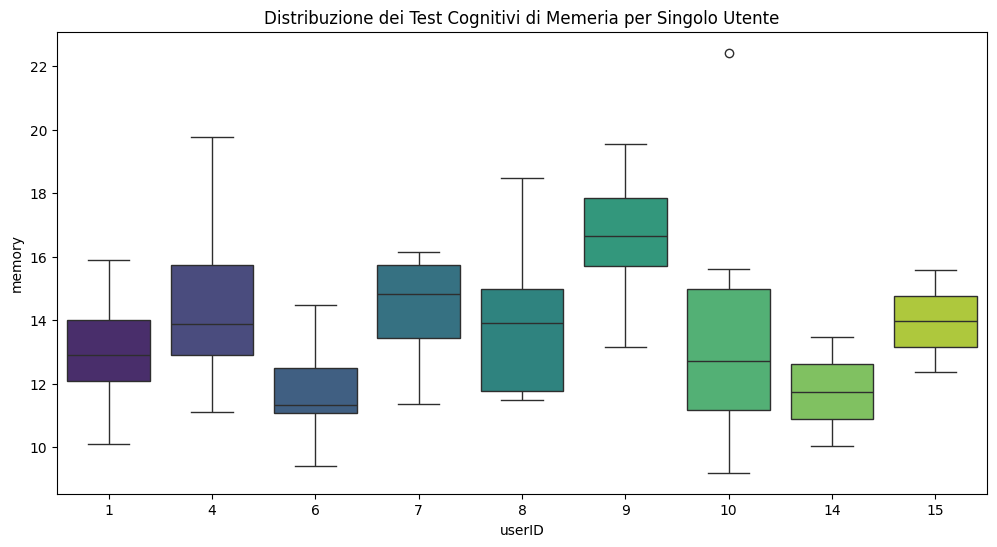

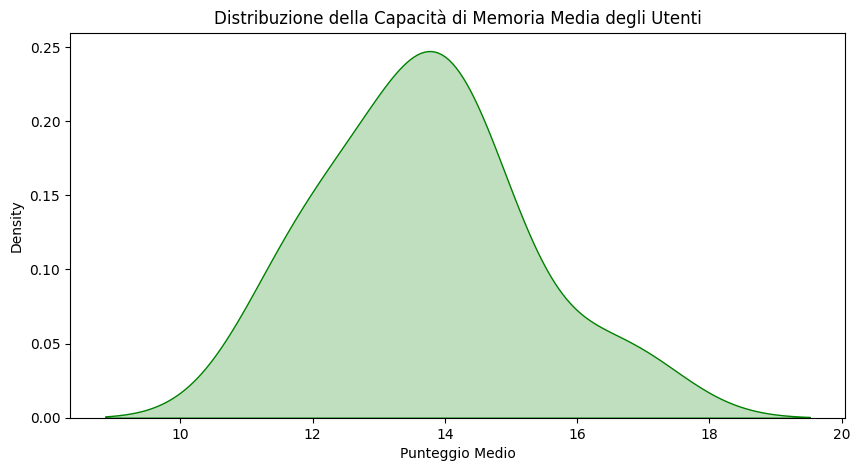

0.33    12.6551
0.66    14.9868
Name: memory, dtype: float64


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='userID', y='memory', palette='viridis')
plt.title('Distribuzione dei Test Cognitivi di Memeria per Singolo Utente')
plt.show()

user_means = df.groupby('userID')['memory'].mean()

plt.figure(figsize=(10, 5))
sns.kdeplot(user_means, fill=True, color='green')
plt.title('Distribuzione della Capacità di Memoria Media degli Utenti')
plt.xlabel('Punteggio Medio')
plt.show()


print(df['memory'].quantile([0.33, 0.66]))

Visti i risultati, per lo score di "memory", possiamo definire le 3 classi. Eseguiremo un processo analogo per gli altri punteggi di C-score(verbal e reasoning). In generale useremo:
- 0 per indicare una performance bassa
- 1 per indicare una performance media
- 2 per indicare una performance alta

In [ ]:
y_reg_mem = y_mem_raw.copy(deep=True) #salvo la colonna per la regressione
y_mem = y_mem_raw.apply(lambda x: 1 if 12.68 <= x <= 14.96 else (0 if x < 12.68 else 2))

Vediamo infine se il dataset è sbilanciato:

In [ ]:
y_mem.value_counts()

,count
memory,
2,29
0,28
1,27


Il dataset non risulta sbilanciato in quanto ogni classe presenta una frequenza quasi identica.

### **Verbal**

stesso proceso ma con score Memoria

/tmp/ipykernel_37725/2931688588.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='userID', y='verbal', palette='viridis')


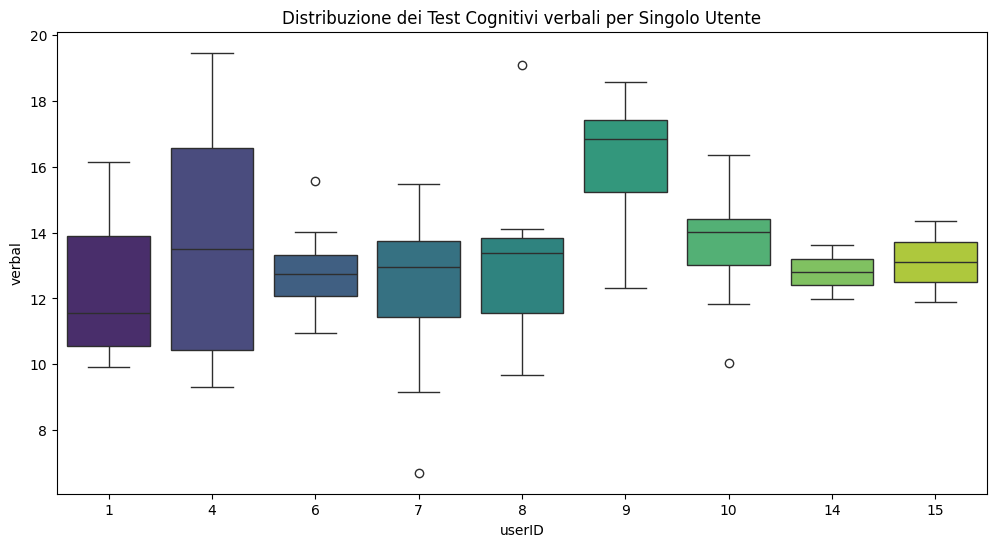

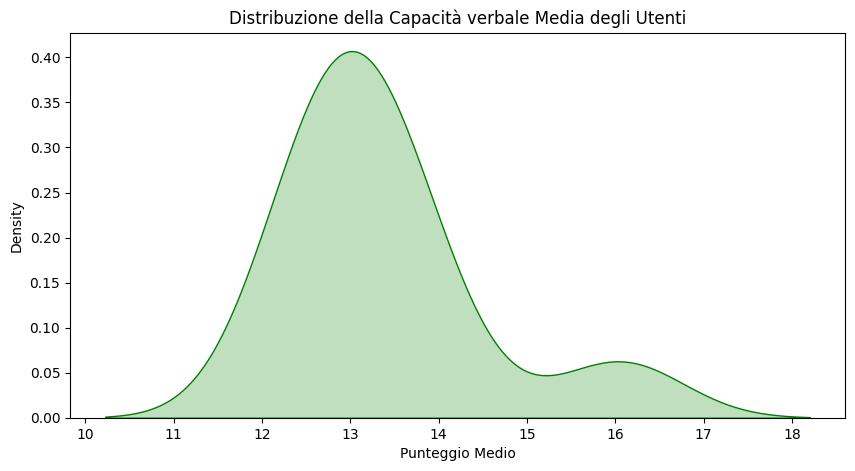

0.33    12.4334
0.66    14.1178
Name: verbal, dtype: float64


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='userID', y='verbal', palette='viridis')
plt.title('Distribuzione dei Test Cognitivi verbali per Singolo Utente')
plt.show()

user_means = df.groupby('userID')['verbal'].mean()

plt.figure(figsize=(10, 5))
sns.kdeplot(user_means, fill=True, color='green')
plt.title('Distribuzione della Capacità verbale Media degli Utenti')
plt.xlabel('Punteggio Medio')
plt.show()


print(df['verbal'].quantile([0.33, 0.66]))

In [ ]:
y_reg_ver = y_ver_raw.copy(deep=True) #salvo la colonna per la regressione
y_ver = y_ver_raw.apply(lambda x: 1 if 12.4 <= x <= 14.11 else (0 if x < 12.4 else 2))

In [ ]:
y_ver.value_counts()

,count
verbal,
2,29
1,28
0,27


le classi sono anche bilanciate qui

### **Reasoning**

stesso proceso che Memoria e Verbal

/tmp/ipykernel_37725/794272430.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='userID', y='reasoning', palette='viridis')


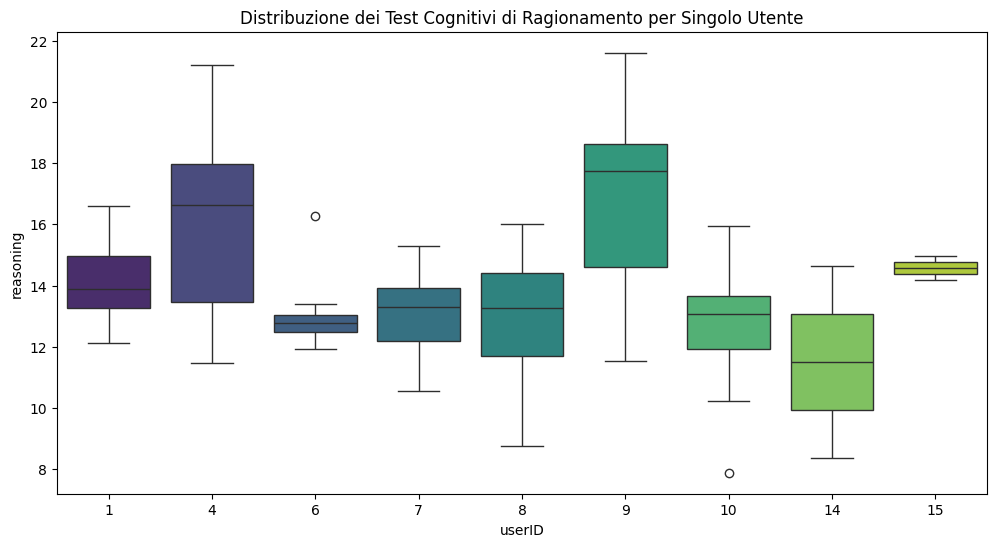

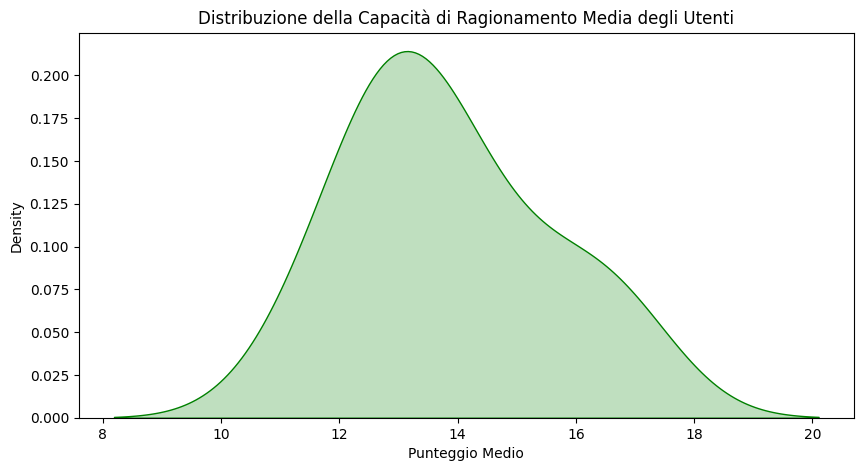

0.33    13.0373
0.66    14.9316
Name: reasoning, dtype: float64


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='userID', y='reasoning', palette='viridis')
plt.title('Distribuzione dei Test Cognitivi di Ragionamento per Singolo Utente')
plt.show()

user_means = df.groupby('userID')['reasoning'].mean()

plt.figure(figsize=(10, 5))
sns.kdeplot(user_means, fill=True, color='green')
plt.title('Distribuzione della Capacità di Ragionamento Media degli Utenti')
plt.xlabel('Punteggio Medio')
plt.show()


print(df['reasoning'].quantile([0.33, 0.66]))

In [ ]:
y_reg_rea = y_rea_raw.copy(deep=True) #salvo la colonna per la regressione
y_rea = y_rea_raw.apply(lambda x: 1 if 13.06 <= x <= 14.93 else (0 if x < 13.06 else 2))

In [ ]:
y_rea.value_counts()

,count
reasoning,
2,29
0,28
1,27


anche bilanciata

##**To do per Classificazione**

unire le 3 y dei diversi tipi di test cognitivi in un y singolo da fare solo dopo vedere che possiamo trovare correlazione con memoria solo.

## **Dummy Models**

Implementiamo il modello baseline, ossia un modello che predice semplicemente la media del target in modo che implementando nuovi modelli, se non superano il risultato del dummy sicuramente non sono utili

**REGRESSOR**

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

#dummy
dummy = DummyRegressor(strategy='mean')

# evaluate
scores = cross_val_score(dummy, X, y_reg_mem, cv=5, scoring='r2')

print("Dummy R2 scores:", scores)
print("Mean Dummy R2:", scores.mean())

Dummy R2 scores: [-0.58672469 -0.03420967 -0.00887179 -1.00952021 -0.04531556]
Mean Dummy R2: -0.336928381642591


### **Split in dati di test e di train**

In [ ]:
# 1. Split dei dati (X sono le tue feature, y_class sono i tuoi 0, 1, 2)
from sklearn.model_selection import train_test_split
y_selected = y_rea   # ------------------ SELEZIONARE QUI IL TARGET DEI MODELLI --------------------------

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_selected, test_size=0.2, random_state=42)

### **Leave-One-Subject-Out (LOSO) Cross-Validation**

Per una valutazione più robusta del modello, specialmente quando si tratta di dati biometrici da diversi individui, utilizzeremo la cross-validation *Leave-One-Subject-Out (LOSO)*. In questo approccio, ad ogni iterazione, i dati di un singolo soggetto vengono messi da parte come set di test, mentre i dati di tutti gli altri soggetti vengono usati per l'addestramento. Questo ci permette di valutare quanto bene il modello generalizza su nuovi individui.

In [ ]:
from sklearn.model_selection import LeaveOneGroupOut
import numpy as np

logo = LeaveOneGroupOut()
groups = X_scaled["userID"].values
print(f"Numero di fold: {logo.get_n_splits(groups=groups)}")

for train_index, test_index in logo.split(X_scaled, y_rea, groups=groups):
    X_train, X_test = X_scaled.iloc[train_index], X_scaled.iloc[test_index]
    y_train, y_test = y_rea.iloc[train_index], y_rea.iloc[test_index]


for i, (train_index, test_index) in enumerate(logo.split(X_scaled, y_rea, groups=groups)): #split restituisce ad ogni iteraz. una lista di posizioni nel dataset per il train e una per il test set
    user_in_test = X_scaled.iloc[test_index]["userID"].unique()

    print(f"--- FOLD {i+1} ---")
    print(f"Utente nel Test Set: {user_in_test}")
    print(f"Numero campioni Training: {len(train_index)}")
    print(f"Numero campioni Test: {len(test_index)}")


Numero di fold: 9
--- FOLD 1 ---
Utente nel Test Set: [1]
Numero campioni Training: 73
Numero campioni Test: 11
--- FOLD 2 ---
Utente nel Test Set: [4]
Numero campioni Training: 67
Numero campioni Test: 17
--- FOLD 3 ---
Utente nel Test Set: [6]
Numero campioni Training: 76
Numero campioni Test: 8
--- FOLD 4 ---
Utente nel Test Set: [7]
Numero campioni Training: 72
Numero campioni Test: 12
--- FOLD 5 ---
Utente nel Test Set: [8]
Numero campioni Training: 77
Numero campioni Test: 7
--- FOLD 6 ---
Utente nel Test Set: [9]
Numero campioni Training: 72
Numero campioni Test: 12
--- FOLD 7 ---
Utente nel Test Set: [10]
Numero campioni Training: 71
Numero campioni Test: 13
--- FOLD 8 ---
Utente nel Test Set: [14]
Numero campioni Training: 82
Numero campioni Test: 2
--- FOLD 9 ---
Utente nel Test Set: [15]
Numero campioni Training: 82
Numero campioni Test: 2


**Funzione Universale per utilizzare la LOSO CV**

In [ ]:
import numpy as np
from sklearn.model_selection import LeaveOneGroupOut

# ==========================================
#  FUNZIONE UNIVERSALE PER VAL. LOSO
# ==========================================
def get_loso_score(model, X, y, scoring_func): #nb: passa X con anche lo userID
    groups_static = X["userID"].values
    # Escludiamo userID dalle feature di train.
    X_features = X.drop(columns=["userID"])

    logo = LeaveOneGroupOut()
    cv_scores = []

    for train_idx, test_idx in logo.split(X_features, y, groups=groups_static):
        X_tr, X_te = X_features.iloc[train_idx], X_features.iloc[test_idx]
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        cv_scores.append(scoring_func(y_te, y_pred))

    return np.mean(cv_scores)



---



# **3. Algoritmo di Selezione Modelli**  

In questa sezione ci occupiamo invece di selezionare un modello misurandone i vari score e facendo feature selection.


I 3 algoritmi che usiamo per la feature selection sono:
1. **Forward Feature Selection**
2. **Backward Feature Selection**
3. **Stepwise Feature Selection**

Sviluppiamo questi tre algoritmi in modo da poterli usare sia per classificatori che per regressori.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.model_selection import LeaveOneGroupOut

# ==========================================
# 1. FORWARD SELECTION (LOSO)
# ==========================================
def forward_sel_loso(model, X, y, scoring_func, minimize=True):
    remaining = [f for f in X.columns if f != "userID"]
    selected = []
    best_score = float('inf') if minimize else float('-inf')

    while remaining:
        feature_scores = []
        for f in remaining:
            curr_cols = selected + [f] + ["userID"]
            score = get_loso_score(model, X[curr_cols], y, scoring_func)
            feature_scores.append((f, score))

        feature_scores.sort(key=lambda x: x[1], reverse=not minimize)
        best_feature, best_score_new = feature_scores[0]

        is_better = (best_score_new < best_score) if minimize else (best_score_new > best_score)

        if is_better:
            selected.append(best_feature)
            remaining.remove(best_feature)
            best_score = best_score_new
            print(f"Forward - Added: {best_feature} | Score: {best_score:.4f}")
        else:
            break

    return selected, best_score

# ==========================================
# 2. BACKWARD SELECTION (LOSO)
# ==========================================
def backward_sel_loso(model, X, y, scoring_func, minimize=True):
    selected = [f for f in X.columns if f != "userID"]

    # Baseline con tutte le feature
    best_score = get_loso_score(model, X[selected + ["userID"]], y, scoring_func)

    while len(selected) > 1:
        scores = []
        for f in selected:
            curr = selected.copy()
            curr.remove(f)
            score = get_loso_score(model, X[curr + ["userID"]], y, scoring_func)
            scores.append((f, score))

        scores.sort(key=lambda x: x[1], reverse=not minimize)
        worst_feature, best_score_new = scores[0]

        is_better = (best_score_new < best_score) if minimize else (best_score_new > best_score)

        if is_better:
            selected.remove(worst_feature)
            best_score = best_score_new
            print(f"Backward - Removed: {worst_feature} | Score: {best_score:.4f}")
        else:
            break

    return selected, best_score

# ==========================================
# 3. STEPWISE SELECTION (LOSO)
# ==========================================
def stepwise_sel_loso(model, X, y, scoring_func, minimize=True):
    remaining = [f for f in X.columns if f != "userID"]
    selected = []
    best_score = float('inf') if minimize else float('-inf')

    while remaining:
        # --- FASE FORWARD ---
        forward_scores = []
        for f in remaining:
            curr = selected + [f] + ["userID"]
            score = get_loso_score(model, X[curr], y, scoring_func)
            forward_scores.append((f, score))

        forward_scores.sort(key=lambda x: x[1], reverse=not minimize)
        best_feature, best_fwd_score = forward_scores[0]

        if (best_fwd_score < best_score) if minimize else (best_fwd_score > best_score):
            selected.append(best_feature)
            remaining.remove(best_feature)
            best_score = best_fwd_score
            print(f"Stepwise (Fwd) - Added: {best_feature} | Score: {best_score:.4f}")
        else:
            break

        # --- FASE BACKWARD ---
        while len(selected) > 1:
            backward_scores = []
            for f in selected:
                curr = [feat for feat in selected if feat != f] + ["userID"]
                score = get_loso_score(model, X[curr], y, scoring_func)
                backward_scores.append((f, score))

            backward_scores.sort(key=lambda x: x[1], reverse=not minimize)
            worst_feature, best_bwd_score = backward_scores[0]

            if (best_bwd_score < best_score) if minimize else (best_bwd_score > best_score):
                selected.remove(worst_feature)
                remaining.append(worst_feature)
                best_score = best_bwd_score
                print(f"Stepwise (Bwd) - Removed: {worst_feature} | Score: {best_score:.4f}")
            else:
                break

    return selected, best_score

## **Algoritmo di selezione Best Model**

Segue l'implementazione di un algoritmo che esegue le seguenti operazioni:

1. Feature Selection con tutti e tre gli algoritmi specificati di sopra(forward,backward e stepwise)
2. Ipertuning con Optuna

Dato che alcuni modelli come Lasso hanno dei punteggi di penalità per le feature poco correlate, quelli li eseguiremo a parte, ma modelli come Random Forest, Linear Regression ecc... necessitano di queste operazioni di F.S.Scriveremo quindi una funzione di optuna separata.



In [ ]:
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor,
    RandomForestClassifier, GradientBoostingClassifier
)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.svm import SVR, SVC

# ==========================================
# SPAZI DEI PARAMETRI (OPTUNA)
# ==========================================

# --- Spazi per modelli ad Albero / Boosting ---
def tree_param_space(trial):
    """Spazio base per Random Forest e Gradient Boosting di Sklearn"""
    return {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 15),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10)
    }

def xgb_param_space(trial):
    """Spazio avanzato per XGBoost con regolarizzazione nativa"""
    return {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True), # L1 (Lasso) interno
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True) # L2 (Ridge) interno
    }

def lgb_param_space(trial):
    """Spazio per LightGBM (estremamente veloce)"""
    return {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', -1, 10), # -1 significa nessun limite
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50)
    }

# --- Spazi per modelli Lineari e Distanza ---
def linear_reg_param_space(trial):
    """Spazio per Ridge Regression (baseline)"""
    return {
        'alpha': trial.suggest_float('alpha', 1e-4, 1e2, log=True) # Forza della regolarizzazione
    }

def linear_clf_param_space(trial):
    """Spazio per Logistic Regression (baseline)"""
    return {
        'C': trial.suggest_float('C', 1e-4, 1e2, log=True), # Inverso della forza di regolarizzazione
        'max_iter': 1000 # Fisso, per garantire convergenza
    }

def svm_param_space(trial):
    """Spazio per Support Vector Machines (buono per confini non lineari complessi)"""
    return {
        'C': trial.suggest_float('C', 1e-3, 1e2, log=True),
        'gamma': trial.suggest_categorical('gamma', ['scale', 'auto']),
        'kernel': trial.suggest_categorical('kernel', ['rbf', 'linear'])
    }

def lasso_reg_param_space(trial):
    """Spazio per Lasso Regression (L1)"""
    return {
        'alpha': trial.suggest_float('alpha', 1e-4, 10.0, log=True)
    }

def lasso_clf_param_space(trial):
    """Spazio per Logistic Regression con penalità L1 (Lasso)"""
    return {
        'C': trial.suggest_float('C', 1e-4, 10.0, log=True),
        'solver': 'liblinear',  # Obbligatorio per usare la penalità L1 in sklearn
        'penalty': 'l1'
    }

ARRAY MODELLI:

In [ ]:
# ==========================================
# ARRAY  MODELLI
# ==========================================

# Modelli REGR.
regression_models = [
    {
        'name': 'XGBoost Regressor',
        'model_class': xgb.XGBRegressor,
        'param_space': xgb_param_space
    },
    {
        'name': 'LightGBM Regressor',
        'model_class': lgb.LGBMRegressor,
        'param_space': lgb_param_space
    },
    {
        'name': 'Random Forest Regressor',
        'model_class': RandomForestRegressor,
        'param_space': tree_param_space
    },
    {
        'name': 'Ridge Regression',
        'model_class': Ridge,
        'param_space': linear_reg_param_space
    },
    {
        'name': 'Support Vector Regressor',
        'model_class': SVR,
        'param_space': svm_param_space
    }
]
# Modelli CLASSIFICAZIONE
classification_models = [
    {
        'name': 'XGBoost Classifier',
        'model_class': xgb.XGBClassifier,
        'param_space': xgb_param_space,
        'static_params': {'random_state': 42}
    },
    {
        'name': 'LightGBM Classifier',
        'model_class': lgb.LGBMClassifier,
        'param_space': lgb_param_space,
        'static_params': {'random_state': 42, 'verbose': -1}
    },
    {
        'name': 'Random Forest Classifier',
        'model_class': RandomForestClassifier,
        'param_space': tree_param_space,
        'static_params': {'random_state': 42}
    },
    {
        'name': 'Logistic Regression',
        'model_class': LogisticRegression,
        'param_space': linear_clf_param_space,
        'static_params': {'random_state': 42, 'max_iter': 2000}
    },
    {
        'name': 'Support Vector Classifier',
        'model_class': SVC,
        'param_space': svm_param_space,
        'static_params': {'random_state': 42}
    }
]



In [ ]:
!pip install optuna
import optuna

# 1. Recuperiamo la funzione obiettivo universale LOSO
def universal_objective_loso(trial, model_class, param_space_func, X, y, scoring_func, static_params):
    # Genera i parametri dinamici dallo spazio definito
    params = param_space_func(trial)
    # Unisce i parametri dinamici con quelli statici (es. random_state, verbose)
    all_params = {**params, **static_params}

    model = model_class(**all_params)
    # Valutazione LOSO (usa la funzione get_loso_score definita in precedenza)
    return get_loso_score(model, X, y, scoring_func)

In [ ]:
from sklearn.metrics import accuracy_score

# 1. Pulizia iniziale (esegui su X_scaled, che è il tuo dataset unico per la LOSO)
if 'height_cm_x' in X_scaled.columns:
    X_scaled.drop(columns=['height_cm_x'], inplace=True)

results_final = {}

for m_info in classification_models:
    name = m_info['name']

    #Un po' brutto perche' non usa dict da sistemare se funziona

    for selection_Method in ["forward_sel_loso", "backward_sel_loso", "stepwise_sel_loso"]:
      print(f"\n{'='*40}\nSTART: {name} {selection_Method}\n{'='*40}")

      # --- STEP A: FEATURE SELECTION (LOSO) ---
      # Usiamo il modello base con parametri statici per selezionare le feature
      static_p = m_info.get('static_params', {})
      base_model = m_info['model_class'](**static_p)

      if selection_Method == "forward_sel_loso":
        print(f"-> Esecuzione Forward Selection...")
        selected_feats, _ = forward_sel_loso(
            model=base_model,
            X=X_scaled,
            y=y_rea,
            scoring_func=accuracy_score,
            minimize=False
        )

      elif selection_Method == "backward_sel_loso":
        print(f"-> Esecuzione Backward Selection...")
        selected_feats, _ = backward_sel_loso(
            model=base_model,
            X=X_scaled,
            y=y_rea,
            scoring_func=accuracy_score,
            minimize=False
        )

      elif selection_Method == "stepwise_sel_loso":
        print(f"-> Esecuzione Stepwise Selection...")
        selected_feats, _ = stepwise_sel_loso(
            model=base_model,
            X=X_scaled,
            y=y_rea,
            scoring_func=accuracy_score,
            minimize=False
        )


      print(f"-> Feature selezionate ({len(selected_feats)}): {selected_feats}")

    # Prepariamo il dataset ridotto (sempre includendo userID per la LOSO)
      X_subset = X_scaled[selected_feats + ["userID"]]

    # --- STEP B: HYPERPARAMETER TUNING (LOSO) ---
      print(f"-> Avvio Tuning Optuna (50 trials)...")
      study = optuna.create_study(direction='maximize')

    # Passiamo lo spazio dei parametri specifico del modello definito nel tuo array
      study.optimize(
          lambda trial: universal_objective_loso(
            trial,
            m_info['model_class'],
            m_info['param_space'],
            X_subset,
            y_rea,
            accuracy_score,
            static_p
        ),
          n_trials=50
      )

      # --- STEP C: FINAL FIT (PRODUZIONE) ---
      print(f"-> Training finale con migliori parametri...")
      best_params = {**study.best_params, **static_p}
      final_model = m_info['model_class'](**best_params)

      # Fit su tutto il dataset, rimuovendo userID
      final_model.fit(X_subset.drop(columns=["userID"]), y_rea)

      # Salviamo tutto in un dizionario per consultazione futura
      results_final[name,selection_Method] = {
        'selected_features': selected_feats,
        'num_selected_features': len(selected_feats),
        'best_params': study.best_params,
        'best_loso_score': study.best_value,
        'model_object': final_model
      }

      print(f"DONE {name} {selection_Method} | Best LOSO Accuracy: {study.best_value:.4f}")





START: XGBoost Classifier forward_sel_loso
-> Esecuzione Forward Selection...
Forward - Added: RR_day_1h_max | Score: 0.4783
Forward - Added: RR_day_1h_peak_mean | Score: 0.5055
Forward - Added: HR_day_1h_energy | Score: 0.5133
Forward - Added: RR_day_1h_q75 | Score: 0.5314
Forward - Added: Carboidrati_4 | Score: 0.5510
Forward - Added: RR_day_1h_q25 | Score: 0.5894
Forward - Added: Proteine_3 | Score: 0.6276
Forward - Added: RR_night_imputed_q75 | Score: 0.6601


[I 2026-05-13 11:00:18,980] A new study created in memory with name: no-name-997198c3-4850-4c62-b4f2-c655565341b3


-> Feature selezionate (8): ['RR_day_1h_max', 'RR_day_1h_peak_mean', 'HR_day_1h_energy', 'RR_day_1h_q75', 'Carboidrati_4', 'RR_day_1h_q25', 'Proteine_3', 'RR_night_imputed_q75']
-> Avvio Tuning Optuna (50 trials)...


[I 2026-05-13 11:00:20,824] Trial 0 finished with value: 0.3673720070778895 and parameters: {'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.0010148741840732961, 'subsample': 0.7382843111695747, 'colsample_bytree': 0.825968713384315, 'reg_alpha': 0.9818451576122054, 'reg_lambda': 4.936693425504744e-07}. Best is trial 0 with value: 0.3673720070778895.
[I 2026-05-13 11:00:22,035] Trial 1 finished with value: 0.4915395062453886 and parameters: {'n_estimators': 395, 'max_depth': 9, 'learning_rate': 0.06319616476751999, 'subsample': 0.70057279289452, 'colsample_bytree': 0.905139098952294, 'reg_alpha': 0.000830994479906738, 'reg_lambda': 0.00012345105995908474}. Best is trial 1 with value: 0.4915395062453886.
[I 2026-05-13 11:00:23,202] Trial 2 finished with value: 0.5403286800345624 and parameters: {'n_estimators': 348, 'max_depth': 8, 'learning_rate': 0.053765005656245854, 'subsample': 0.8656061144691554, 'colsample_bytree': 0.8188801250044024, 'reg_alpha': 0.0015127855341123804, '

-> Training finale con migliori parametri...
DONE XGBoost Classifier forward_sel_loso | Best LOSO Accuracy: 0.6090

START: XGBoost Classifier backward_sel_loso
-> Esecuzione Backward Selection...
Backward - Removed: RR_night_imputed_q25 | Score: 0.4113
Backward - Removed: Carboidrati_4 | Score: 0.4364
Backward - Removed: carbs_over_proteins_4 | Score: 0.4643
Backward - Removed: RR_night_imputed_kurtosis | Score: 0.4782
Backward - Removed: HR_night_imputed_q25 | Score: 0.4801


...

-> Training finale con migliori parametri...
DONE Support Vector Classifier backward_sel_loso | Best LOSO Accuracy: 0.5541

START: Support Vector Classifier stepwise_sel_loso
-> Esecuzione Stepwise Selection...
Stepwise (Fwd) - Added: RR_day_1h_q75 | Score: 0.5386
Stepwise (Fwd) - Added: Kcal_3 | Score: 0.5930
Stepwise (Fwd) - Added: HR_day_1h_iqr | Score: 0.6189
Stepwise (Fwd) - Added: Carboidrati_3 | Score: 0.6395
Stepwise (Fwd) - Added: RR_day_1h_std_diff | Score: 0.6871
Stepwise (Bwd) - Removed: Kcal_3 | Score: 0.6902
Stepwise (Fwd) - Added: RR_day_1h_mean_abs_diff | Score: 0.7002


[I 2026-05-13 12:23:27,696] A new study created in memory with name: no-name-1e13cf31-03f9-4e42-87b5-ba2d21a20038
[I 2026-05-13 12:23:27,740] Trial 0 finished with value: 0.4846683817272052 and parameters: {'C': 89.50229179306113, 'gamma': 'auto', 'kernel': 'rbf'}. Best is trial 0 with value: 0.4846683817272052.
[I 2026-05-13 12:23:27,783] Trial 1 finished with value: 0.20055108290402407 and parameters: {'C': 0.016520402882136246, 'gamma': 'scale', 'kernel': 'linear'}. Best is trial 0 with value: 0.4846683817272052.
[I 2026-05-13 12:23:27,823] Trial 2 finished with value: 0.681578769814064 and parameters: {'C': 21.362000292573494, 'gamma': 'scale', 'kernel': 'rbf'}. Best is trial 2 with value: 0.681578769814064.
[I 2026-05-13 12:23:27,865] Trial 3 finished with value: 0.19099119834413952 and parameters: {'C': 0.0024025620140122952, 'gamma': 'auto', 'kernel': 'rbf'}. Best is trial 2 with value: 0.681578769814064.


-> Feature selezionate (5): ['RR_day_1h_q75', 'HR_day_1h_iqr', 'Carboidrati_3', 'RR_day_1h_std_diff', 'RR_day_1h_mean_abs_diff']
-> Avvio Tuning Optuna (50 trials)...


[I 2026-05-13 12:23:27,912] Trial 4 finished with value: 0.3558233705292529 and parameters: {'C': 0.4789056906295903, 'gamma': 'auto', 'kernel': 'linear'}. Best is trial 2 with value: 0.681578769814064.
[I 2026-05-13 12:23:27,957] Trial 5 finished with value: 0.43262075615016793 and parameters: {'C': 0.10404885335189124, 'gamma': 'auto', 'kernel': 'linear'}. Best is trial 2 with value: 0.681578769814064.
[I 2026-05-13 12:23:27,997] Trial 6 finished with value: 0.6716094363153187 and parameters: {'C': 0.9068759969920418, 'gamma': 'scale', 'kernel': 'rbf'}. Best is trial 2 with value: 0.681578769814064.
[I 2026-05-13 12:23:28,051] Trial 7 finished with value: 0.19099119834413952 and parameters: {'C': 0.018860854486196222, 'gamma': 'scale', 'kernel': 'rbf'}. Best is trial 2 with value: 0.681578769814064.
[I 2026-05-13 12:23:28,099] Trial 8 finished with value: 0.48858576064458414 and parameters: {'C': 45.93296369847182, 'gamma': 'auto', 'kernel': 'rbf'}. Best is trial 2 with value: 0.6815

-> Training finale con migliori parametri...
DONE Support Vector Classifier stepwise_sel_loso | Best LOSO Accuracy: 0.7068


## Correlazione tra le features

In [ ]:

# -------------   da gemini- CONTROLLARE -----------------
# 1. Uniamo i dati in un DataFrame temporaneo
df_temp = X_train.copy()
df_temp['TARGET_MEMORY'] = y_train

# 2. Definiamo le feature emerse dai modelli
features_of_interest = [
    'height_cm_x', 'sex_x',
    'HR_night_imputed_std_diff', 'HR_day_1h_max_abs_diff', 'HR_day_1h_rms',
    'RR_night_imputed_rms', 'RR_day_1h_std',
    'RR_night_imputed_max_abs_diff',
    'Proteine_2', 'Grassi_4', 'carbs_over_proteins_1'
]

# Filtriamo solo le feature effettivamente presenti in X_train per evitare errori
features_presenti = [f for f in features_of_interest if f in df_temp.columns]

# 3. Calcoliamo la matrice di correlazione di Spearman
corr_matrix = df_temp[features_presenti + ['TARGET_MEMORY']].corr(method='spearman')

# 4. Isoliamo e ordiniamo la forza della correlazione (in valore assoluto) rispetto al target
target_corr = corr_matrix['TARGET_MEMORY'].drop('TARGET_MEMORY')

print("--- FORZA DELLA CORRELAZIONE (Spearman rho) CON C-SCORE MEMORY ---")
print(target_corr.sort_values(key=abs, ascending=False))

--- FORZA DELLA CORRELAZIONE (Spearman rho) CON C-SCORE MEMORY ---
RR_night_imputed_rms             0.204506
RR_day_1h_std                    0.171783
sex_x                            0.169047
RR_night_imputed_max_abs_diff   -0.123658
height_cm_x                      0.114057
HR_day_1h_rms                    0.092901
HR_night_imputed_std_diff       -0.062349
Proteine_2                       0.026849
carbs_over_proteins_1            0.011230
Grassi_4                        -0.009365
HR_day_1h_max_abs_diff          -0.004990
Name: TARGET_MEMORY, dtype: float64


## Generazione csv con I resultati dei algoritmi di selezione per analizzare

In [ ]:
import pandas as pd

rows = []

for (model_name, selection_method), result in results_final.items():

    row = {
        "model": model_name,
        "selection_method": selection_method,
        "num_selected_features": result["num_selected_features"],
        "selected_features": ", ".join(result["selected_features"]),
        "best_loso_score": result["best_loso_score"]
    }

    # agiunge iperparametri
    for param_name, param_value in result["best_params"].items():
        row[f"param_{param_name}"] = param_value

    rows.append(row)

# Crea Dataframe
risultati = pd.DataFrame(rows)

# Salva CSV
risultati.to_csv(
    "/content/drive/MyDrive/risultati.csv",
    index=False
)
print(risultati)

                        model   selection_method  num_selected_features  \
0          XGBoost Classifier   forward_sel_loso                      8   
1          XGBoost Classifier  backward_sel_loso                    117   
2          XGBoost Classifier  stepwise_sel_loso                      8   
3         LightGBM Classifier   forward_sel_loso                      2   
4         LightGBM Classifier  backward_sel_loso                    118   
5         LightGBM Classifier  stepwise_sel_loso                      2   
6    Random Forest Classifier   forward_sel_loso                      1   
7    Random Forest Classifier  backward_sel_loso                    120   
8    Random Forest Classifier  stepwise_sel_loso                      1   
9         Logistic Regression   forward_sel_loso                      6   
10        Logistic Regression  backward_sel_loso                    112   
11        Logistic Regression  stepwise_sel_loso                      6   
12  Support Vector Classi